In [ ]:
import os
import glob
import xarray as xr
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
import string
import rpy2.robjects as robjects
import csv

# Locate the path to where the input files are stored
input_directory = "/mnt/CORDEX_CMIP6_tmp/user_tmp/jbediajimenez/fwi_val_results/monthly_bias/monthly_data"
output_figure_path = "../figures/"

# Read all the .Rdata files into a dictionary (17 models + ERA5):

FWI_all = {} # Empty dictionary to fill in

files = sorted(glob.glob(f"{input_directory}/*fwi_monthly.Rdata"))

for f in files:

    model_name = os.path.basename(f).replace("_fwi_monthly.Rdata", "")

    # Load the RData file into R's environment and pull the object out by its loaded name (monthly_fwi)
    obj = robjects.r[list(robjects.r['load'](f))[0]]

    # Extract the dimensions
    data = np.array(obj.rx2('Data')) # shape (time, lat, lon)
    lons = np.array(obj.rx2('xyCoords').rx2('x'))
    lats = np.array(obj.rx2('xyCoords').rx2('y'))
    dates_start = pd.to_datetime(list(obj.rx2('Dates').rx2('start')))

    # Wrap as xarray (lat forced ascending so the PRUDENCE slices work)
    da = xr.DataArray(
        data,
        dims=["time", "lat", "lon"],
        coords={"time": dates_start, "lat": lats, "lon": lons},
        name="FWI"
    ).sortby("lat")

    # Select JJA (Jun/Jul/Aug), 1980-2020, and average over time -> one 2D (lat, lon) field
    t = da.time
    FWI_all[model_name] = da.sel(
        time = (t.dt.year >= 1980) & (t.dt.year <= 2020) & (t.dt.month.isin([6, 7, 8]))
    ).mean("time", skipna = True)
    
    print(model_name)


AUTH_WRF451Q
CLMcom-CMCC_CCLM6-0-1-URB
CLMcom-Hereon_CCLM6-0-1
CLMcom-Hereon_GCOAST-AHOIB1-1
CLMcom-Hereon_ICON-CLM-202407-1-1
CLMcom-KUL_CCLM6-0-1-URB-ESG
CNRM_ALADIN64E1
DWD-BSH_ROAM-NBS
ERA5-Land
GERICS_REMO2020-2-2-TEB
GERICS_REMO2020-2-2-iMOVE-LUC
GERICS_REMO2020-2-2-iMOVE
GERICS_REMO2020-2-2
HCLIMcom-SMHI_HCLIM43-ALADIN
ICTP_RegCM5-0
IDL-FCUL_WRF451Q
KNMI_RACMO23E
RMIB-UGent_ALARO1-SFX


In [10]:
# Read in the PRUDENCE regions

with open("../docs/prudence_regions.csv") as f:
    prudence_region_coords = {
        row["abbreviation"]: {
            "lon": slice(float(row["lon_min"]), float(row["lon_max"])),
            "lat": slice(float(row["lat_min"]), float(row["lat_max"])),
        }
        for row in csv.DictReader(f)
    }


In [11]:
# Create an empty data frame to fill inside the for loop

FWI_PRUDENCE = pd.DataFrame(columns = ["region", "model", "mean_value"])

# Calculate the JJA-mean FWI over the PRUDENCE regions and take the weighted averages

all_model_names = list(FWI_all.keys()) 

for model_name in all_model_names:

    field = FWI_all[model_name]

    # Assign the weights based on the cosine of the latitude, as it is proportional to the grid cell area

    weights = np.cos(np.deg2rad(field.lat))
    weights.name = "weights"

    # Crop the data over the PRUDENCE regions

    prudence_bi = field.sel(prudence_region_coords["BI"])
    prudence_sc = field.sel(prudence_region_coords["SC"])
    prudence_fr = field.sel(prudence_region_coords["FR"])
    prudence_me = field.sel(prudence_region_coords["ME"])
    prudence_al = field.sel(prudence_region_coords["AL"])
    prudence_ea = field.sel(prudence_region_coords["EA"])
    prudence_ip = field.sel(prudence_region_coords["IP"])
    prudence_md = field.sel(prudence_region_coords["MD"])
    prudence_nee = field.sel(prudence_region_coords["NEE"])
    prudence_eap = field.sel(prudence_region_coords["EAP"])
    prudence_mbs = field.sel(prudence_region_coords["MBS"])

    # Take the weighted means over the PRUDENCE regions and assign them to the data frame

    new_df = {"region": ["BI", "SC", "FR", "ME", "AL", "EA", "IP", "MD", "NEE", "EAP", "MBS"],
              "model": model_name,
              "mean_value": [prudence_bi.weighted(weights).mean(("lon", "lat"), skipna = True).values,
                             prudence_sc.weighted(weights).mean(("lon", "lat"), skipna = True).values,
                             prudence_fr.weighted(weights).mean(("lon", "lat"), skipna = True).values,
                             prudence_me.weighted(weights).mean(("lon", "lat"), skipna = True).values,
                             prudence_al.weighted(weights).mean(("lon", "lat"), skipna = True).values,
                             prudence_ea.weighted(weights).mean(("lon", "lat"), skipna = True).values,
                             prudence_ip.weighted(weights).mean(("lon", "lat"), skipna = True).values,
                             prudence_md.weighted(weights).mean(("lon", "lat"), skipna = True).values,
                             prudence_nee.weighted(weights).mean(("lon", "lat"), skipna = True).values,
                             prudence_eap.weighted(weights).mean(("lon", "lat"), skipna = True).values,
                             prudence_mbs.weighted(weights).mean(("lon", "lat"), skipna = True).values]
              }

    FWI_PRUDENCE = pd.concat([FWI_PRUDENCE, pd.DataFrame(new_df)], ignore_index = True)

# Correct the type of the column

FWI_PRUDENCE["mean_value"] = FWI_PRUDENCE["mean_value"].astype("float")


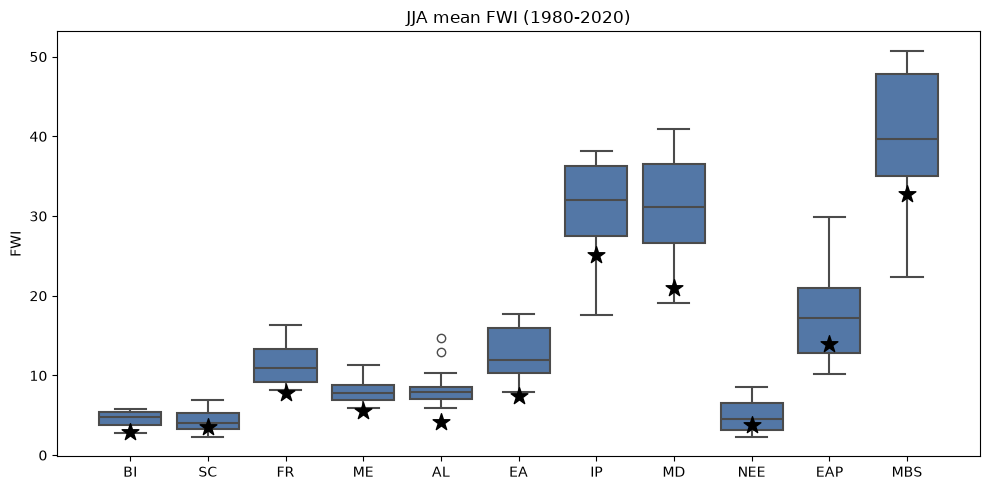

In [12]:
# Draw the boxplot for the PRUDENCE regions

region_order = ["BI", "SC", "FR", "ME", "AL", "EA", "IP", "MD", "NEE", "EAP", "MBS"]

# Split the models from the ERA5 reference

is_era5 = FWI_PRUDENCE["model"].str.contains("ERA5")
models_df = FWI_PRUDENCE[~is_era5]
era5_df   = FWI_PRUDENCE[is_era5].set_index("region").reindex(region_order)

fig, ax = plt.subplots(figsize=(10, 5))

# Boxplot: spread across the climate models
sns.boxplot(data = models_df, x = "region", y = "mean_value", order = region_order,
            linewidth = 1.5, color = "#4575b4", ax = ax)

# Overlay ERA5 as a reference marker at each region's categorical x-position
ax.scatter(range(len(region_order)), era5_df["mean_value"].values,
           marker = "*", s = 160, color = "black", zorder = 5, label = "ERA5-Land")

ax.set_title("JJA mean FWI (1980-2020)")
ax.set_ylabel("FWI")
ax.set_xlabel("")

plt.tight_layout()

plt.savefig((output_figure_path + "fwi_jja_prudence_regions_boxplot"), dpi = 600)


In [13]:
# Calculate the median values over the PRUDENCE regions across the models (ERA5 excluded)

median_tbl = (
    FWI_PRUDENCE
    .groupby(['region'])['mean_value']
    .median()
    .reset_index()
    .sort_values(['region'])
)

median_tbl

,region,mean_value
0,AL,7.738430
1,BI,4.531377
2,EA,11.465554
3,EAP,17.212638
4,FR,10.839823
5,IP,31.599684
6,MBS,38.657847
7,MD,30.058533
8,ME,7.732926
9,NEE,4.419758
